Commit History can be found here: https://github.com/vigneshK0404/Data_Science_Projects.git

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import Bounds, minimize, curve_fit
import contourpy
from scipy.stats import cauchy, expon, chi2

## 1 . Read Data

In [2]:
df = pd.read_csv("data/Project2_Set4.txt", header=None).astype(float)

## 2 . Number of Photons

In [3]:
N_photons = len(df)
print(f"Total number of photons: {N_photons}")

E_outlier_limit = np.percentile(df[0],99)

Total number of photons: 473


## 3 . Likelihood Function
$\displaystyle \mathcal{L} = \prod_{i=0}^{n} \left[\frac{n_s}{N\pi\Gamma\left[1+(\frac{E_i-E_0}{\Gamma})^2 \right]} + \frac{n_b\exp(\frac{-E_i}{E_b})}{N E_b}\right]$

## 4 . Histogram of Photon Energies

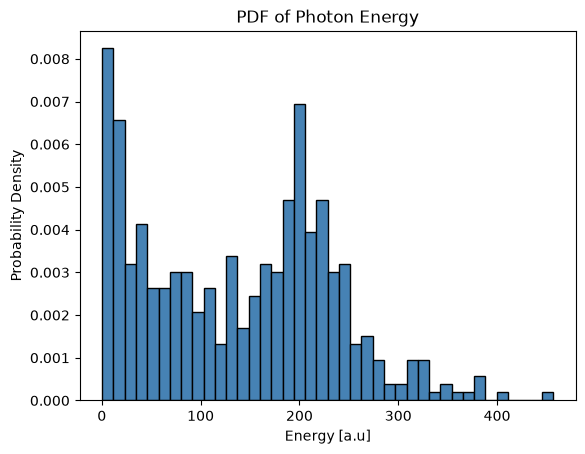

In [4]:
plt.hist(df[0][df[0]<E_outlier_limit], bins=40, edgecolor="black", color="steelblue", density=True)
plt.xlabel("Energy [a.u]")
plt.ylabel("Probability Density")
plt.title("PDF of Photon Energy")
plt.show()

## 5 . Paramater Estimation using Likelihood Extremization

In [5]:
Eb = 100

def signal(ns, G, E0, E) -> np.array:
    return (ns/N_photons)*cauchy.pdf(E, loc=E0, scale=G)

def background(nb, E) -> np.array:
    return (nb/N_photons)*expon.pdf(E, loc=0, scale=Eb)

def complete_pdf(x, E):
    ns, nb, E0 ,G = x
    return signal(ns,G,E0, E) + background(nb, E)

def loglikelihood(x, E) -> float:
    return -2*np.sum(np.log(complete_pdf(x,E)), axis=0)

def ll_wrapper(x, ns, nb, G, E):
    E0 = x[0]
    x_list = [ns, nb, E0, G]
    return loglikelihood(x_list,E)

def total_photons_constraint(x):
    return x[0] + x[1] - N_photons

In [6]:
ns_bound = [0,N_photons]
nb_bound = [0,N_photons]
E0_bound = [0,np.inf]
G_bound = [0,np.inf]

ns_init = N_photons/2
nb_init = N_photons/2
E0_init = 200
G_init = 10
init_vals = [ns_init, nb_init, E0_init, G_init]

bound_arr = [ns_bound,nb_bound, E0_bound, G_bound]

cons = {'type':'eq', 'fun': total_photons_constraint}

In [7]:
E = np.array(df[0])
min_params = minimize(loglikelihood, x0=init_vals, args=E ,method="SLSQP", bounds=bound_arr, constraints=cons)
ns, nb, E0, G = min_params.x
ns = round(ns)
nb = round(nb)
print(f"NSignal: {ns} \nNBackground:{nb} \nE0:{E0:.3f} \n\u0393:{G:.3f}")

NSignal: 180 
NBackground:293 
E0:206.003 
Γ:21.840


## 6 . Overlaid Best Fits

In [8]:
Energy_centers = np.linspace(0,E_outlier_limit,473)
ns, nb, E0 ,G = min_params.x
pred_total = complete_pdf(min_params.x,Energy_centers)
pred_signal = signal(ns,G,E0,Energy_centers)
pred_background = background(nb, Energy_centers)

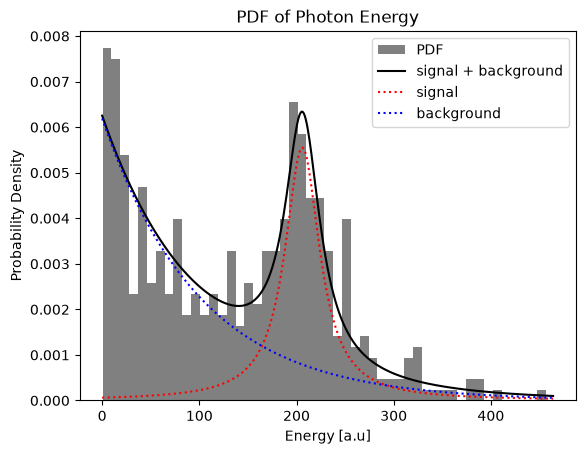

In [9]:
plt.hist(df[0][df[0]<E_outlier_limit], bins=50, density=True, label="PDF", color="grey")
plt.plot(Energy_centers, pred_total,color="black", label="signal + background")
plt.plot(Energy_centers, pred_signal,linestyle="dotted",color="red", label="signal")
plt.plot(Energy_centers, pred_background,linestyle="dotted" ,color="blue", label="background")
plt.xlabel("Energy [a.u]")
plt.ylabel("Probability Density")
plt.title("PDF of Photon Energy")
plt.legend()
plt.show()

## 7 . Minimum Negative Log Likelihood Contour

In [10]:
dim = 500
E0_min, E0_max = 180,220
G_min,G_max = 15,35

E0_arr = np.linspace(E0_min, E0_max, dim)
G_arr = np.linspace(G_min,G_max,dim)
E0_grid , G_grid = np.meshgrid(E0_arr, G_arr)
E0_grid_bcast = E0_grid[None,:,:]
G_grid_bcast = G_grid[None,:,:]
E_grid = E[:,None,None]

x_grid = [ns,nb,E0_grid_bcast,G_grid_bcast]
minimumll = loglikelihood(min_params.x,E)
ll_map = loglikelihood(x_grid, E_grid)

In [11]:
level = minimumll + 1
gen = contourpy.contour_generator(E0_grid, G_grid, ll_map) # contourpy works on meshgrids
lines = gen.lines(level)  # list of segments of the contour

if len(lines) == 0:
    raise RuntimeError("No contour found at this level: enlarge the scan range.")
for seg in lines:
    if not np.allclose(seg[0], seg[-1]):
        print("WARNING: the contour touches the edge of the scan -> enlarge the range.")

verts = np.vstack(lines)

E0_minus_unc, E0_plus_unc = verts[:, 0].min(), verts[:, 0].max()
G_minus_unc,  G_plus_unc = verts[:, 1].min(), verts[:, 1].max()

print('The scan of the -2log(L) map results in:')
print('     mu     = {:.3f} +{:.3f} / -{:.3f}'.format(E0, E0_plus_unc - E0, E0 - E0_minus_unc))
print('     sigma  = {:.3f} +{:.3f} / -{:.3f}'.format(G, G_plus_unc - G, G - G_minus_unc))
print('The errors from a -2log(L) scan do not have to be symmetric')


The scan of the -2log(L) map results in:
     mu     = 206.003 +3.018 / -2.932
     sigma  = 21.840 +2.759 / -2.471
The errors from a -2log(L) scan do not have to be symmetric


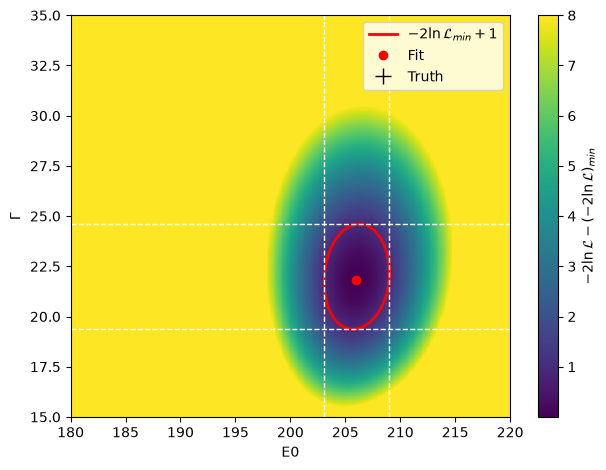

In [12]:
fig, ax = plt.subplots()
im = ax.pcolormesh(E0_grid, G_grid, ll_map - minimumll,
                  shading='nearest', 
                    vmax=8)
fig.colorbar(im, ax=ax, label=r'$-2\ln\mathcal{L} - (-2\ln\mathcal{L})_{min}$')

for k, seg in enumerate(lines):
    ax.plot(seg[:, 0], seg[:, 1], 'r-', lw=2,
            label=r'$-2\ln\mathcal{L}_{min}+1$' if k == 0 else None)

# Draw the boundaries of the ellipse
ax.axvline(E0_minus_unc, color='w', ls='dashed', lw=1)
ax.axvline(E0_plus_unc, color='w', ls='dashed', lw=1)
ax.axhline(G_minus_unc, color='w', ls='dashed', lw=1)
ax.axhline(G_plus_unc, color='w', ls='dashed', lw=1)

# beautifications, truth and central values.
ax.plot(E0, G, 'ro', label='Fit')
ax.plot(0., 1., 'k+', ms=12, label='Truth')
ax.set_xlabel("E0")
ax.set_ylabel(r'$\Gamma$')
ax.set_xlim(E0_min, E0_max)
ax.set_ylim(G_min, G_max)
ax.legend(loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()

## 8 . Simulation for Estimator Testing

In [13]:
def E0_bestFit_unc(num_repeats, min_measurements, max_measurements, step_size):
    ns_set = np.arange(min_measurements,max_measurements,step_size,dtype=int)
    nb_set = max_measurements - ns_set
    G_mc = 200
    E0_centrals = []
    E0_stds = []
    init_vals_iter = [E0_init]
    bounds_arr_iter = [E0_bound]
    num_repeats = 50
    for ns_i, nb_i in zip(ns_set,nb_set):
        E_sig = cauchy.rvs(loc=E0, scale=G_mc, size=(num_repeats,ns_i))
        E_bkg = expon.rvs(loc=0, scale=Eb, size=(num_repeats,nb_i))
        E_total = np.concatenate((E_sig,E_bkg), axis=1)
        E0_fits = []
        for E_iter in E_total:
            min_params = minimize(ll_wrapper, x0=init_vals_iter, args=(ns_i, nb_i, G_mc, E_iter) ,method="SLSQP", bounds=bounds_arr_iter)
            if(min_params.success):
                E0_fits.append(min_params.x)
        E0_centrals.append(np.mean(E0_fits))
        E0_stds.append(np.std(E0_fits,ddof=1))

    return ns_set, E0_centrals, E0_stds

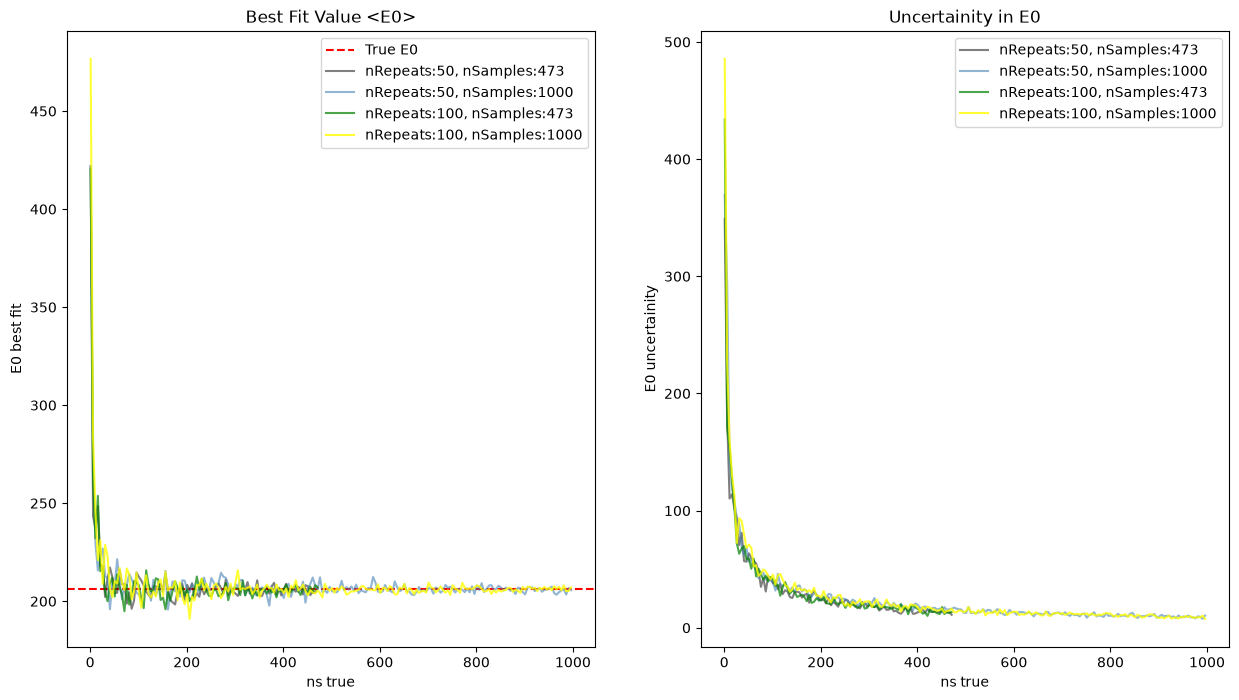

In [14]:
num_repeats_list = [50,100]
step_size = 5
min_measurement = 1
max_measurement_list = [473,1000]

fig,axes = plt.subplots(ncols=2, figsize=(15,8))
axes[0].set_title("Best Fit Value <E0>")
axes[0].set_xlabel("ns true")
axes[0].set_ylabel("E0 best fit")
axes[0].axhline(y=E0, color='red', linestyle='--', label='True E0')

axes[1].set_title("Uncertainity in E0")
axes[1].set_xlabel("ns true")
axes[1].set_ylabel("E0 uncertainity")

alpha = 0.5
colors = ["black", "steelblue", "green", "yellow"]
color_idx = 0
for num_repeats in num_repeats_list:
    for max_measurement in max_measurement_list:
        ns_set, E0_centrals, E0_stds = E0_bestFit_unc(num_repeats, min_measurement, max_measurement, step_size)
        axes[0].plot(ns_set, E0_centrals, color=colors[color_idx],alpha=alpha,label=f"nRepeats:{num_repeats}, nSamples:{max_measurement}")
        axes[1].plot(ns_set, E0_stds, color=colors[color_idx],alpha=alpha,label=f"nRepeats:{num_repeats}, nSamples:{max_measurement}")
        alpha += 0.1
        color_idx += 1
        

axes[0].legend()
axes[1].legend()
plt.show()

Yes, the estimator is consistent and unbiased. The above plot shows that as the number of repeats and samples increased the Estimator gets closer to the true value. num_repeats corresponds to, how many sets of data I generate for a given true ns, nSamples corresponds to how many samples I generate per run. 

# Chi-Square Fitting

## 1 . Photon Energy PDF

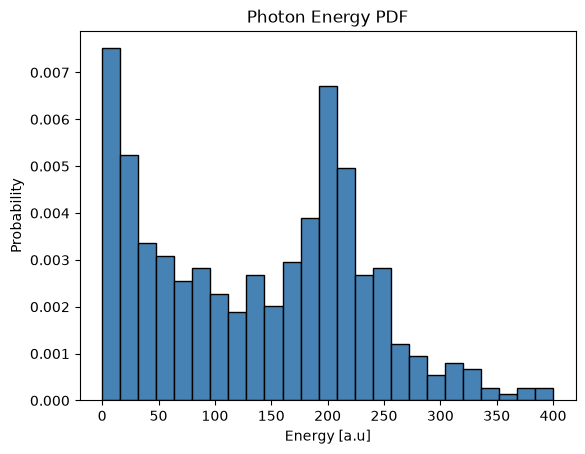

In [15]:
minE, maxE = 0,400
nsteps = 26
bins_arr = np.linspace(minE,maxE,nsteps)
plt.hist(E,bins_arr, edgecolor="black",color="steelblue", density=True)
plt.xlabel("Energy [a.u]")
plt.ylabel("Probability")
plt.title("Photon Energy PDF")
plt.show()

## 2 . Binned $\chi ^2$ Fit

In [16]:
def chi_sq_fit(x,E,bins_arr):
    n, _ = np.histogram(E, bins_arr)
    E_central_vals = (bins_arr[:-1] + bins_arr[1:])/2
    bin_widths = np.diff(bins_arr)
    central_values = N_photons*complete_pdf(x,E_central_vals)*bin_widths
    chi_sq = np.sum(np.square(n - central_values)/central_values)
    return chi_sq

In [17]:
min_params_chi = minimize(chi_sq_fit, x0=init_vals, args=(E,bins_arr) ,method="SLSQP", bounds=bound_arr, constraints=cons)
ns, nb, E0, G = min_params_chi.x
ns = round(ns)
nb = round(nb)

chi2min = chi_sq_fit(min_params_chi.x,E,bins_arr)
ndof = len(bins_arr)-1 - 4
print(f"NSignal: {ns:.3f}, NBackground:{nb:.3f}, E0:{E0:.3f}, \u0393:{G:.3f}")
print(f"chi2_min/ndof : {chi2min:.3f}/{ndof} = {chi2min/ndof :.3f}")

NSignal: 197.000, NBackground:276.000, E0:205.540, Γ:25.434
chi2_min/ndof : 17.281/21 = 0.823


## 3 . p-value 

In [18]:
print("The p-value for this fit is {:.4f}".format(1-chi2.cdf(chi2min,ndof)))

The p-value for this fit is 0.6939


## 4. Answers

The chi2 fit resulted in the same fit parameters as MLE. But, I would not immidiately trust the p-value here, the amount of statistics we have is not large. Small bin counts affect the residual calculation. 